# CargoSense — Phase 9: AdaBoost Baseline & Custom Experiments
## Sequential Adaptive Boosting for Partial-Truckload (PTL) Conversion Prediction

**Project:** CargoSense Opportunity Detection Engine (ODE)  
**Phase:** Phase 9 (Candidate Model Evaluation & Benchmarking)  
**Experiment Lead:** Adaptive Boosting Lead  
**Experiments:** Run 5 (Baseline AdaBoost) & Run 6 (Custom AdaBoost)  
**Primary Metric:** PR-AUC (Precision-Recall Area Under Curve) for Severe Class Imbalance  
**Input Partitions:** `data/processed/phase8_{train,val,test}.csv`  
**Preprocessor:** `models/phase8_preprocessor.joblib` (Baseline) & `models/phase9/adaboost/custom/preprocessor.joblib` (Custom)  
**Saved Artifacts:** `models/phase9/adaboost/{baseline,custom}/` and `reports/phase9/adaboost/{baseline,custom}/`  

---

## 1. Experiment Objectives & Context

In the CargoSense Opportunity Detection Engine (ODE), candidate consolidation packages are generated to combine pending Partial-Truckload (PTL) shipments onto available line-haul vehicles. Our machine learning objective is to predict whether a proposed candidate combination will successfully convert into a Full-Truckload dispatch (`Became_FTL = 1`) prior to departure cutoff.

In **Phase 9**, we evaluate **Adaptive Boosting (AdaBoost)** as a sequential ensemble technique that iteratively focuses on misclassified boundary instances:
- **Run 5 (Baseline AdaBoost)**: Evaluates AdaBoost on the 14 shared Phase 8 baseline features (11 numerical, 3 categorical), preprocessed via the frozen `models/phase8_preprocessor.joblib`.
- **Run 6 (Custom AdaBoost)**: Evaluates whether incorporating exactly four physical ratio and packaging density features (`cargo_density_kg_m3`, `weight_fill_ratio`, `volume_fill_ratio`, `avg_unit_weight_kg`) improves boosting discrimination and calibration.

### Methodological Guardrails:
1. **Identical Splitting**: Strict chronological, shipment-grouped partitions (Train: Days 1–62, Val: Days 63–75, Test: Days 76–89). Competing candidate combinations remain grouped together.
2. **Zero Target Leakage**: Excludes post-cutoff metrics, surrogate IDs, timestamps, and candidate strategies.
3. **Class Imbalance Strategy**: Employs balanced sample weighting on training data ($w_0 \approx 0.5506, w_1 \approx 5.4362$) to penalize minority misclassifications without synthetic data distortion.
4. **Validation-Guided Model Selection**: Primary ranking metric is validation PR-AUC. Threshold tuning is frozen on validation data before evaluating held-out test data.
5. **Preservation of Experiment Isolation**: Run 5 and Run 6 are benchmarked against each other. No cross-model comparisons with Random Forest or XGBoost are conducted here.

In [1]:
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Add project root to sys.path
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models.evaluation import (
    compute_binary_metrics,
    find_optimal_threshold,
    plot_pr_curves,
    plot_roc_curves,
    plot_confusion_matrices,
    plot_feature_importances,
    plot_calibration_curves
)

warnings.filterwarnings("ignore", category=UserWarning)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

print("Phase 9 AdaBoost Environment Initialized Successfully.")
print(f"Project root: {PROJECT_ROOT}")

Phase 9 AdaBoost Environment Initialized Successfully.
Project root: C:\Sameera-sem5\Projects\Cargosense


## 2. Dataset and Partition Inspection

We load the chronological shipment-grouped partitions created in Phase 8 (`data/processed/phase8_{train,val,test}.csv`) and verify:
1. Row counts and feature dimensionality.
2. Positive class prevalence across train, validation, and test splits.
3. Grouped candidate integrity: all competing candidate combinations for a given parent shipment must reside in the exact same partition.
4. Absence of data leakage and prohibited operational columns.

In [2]:
data_dir = PROJECT_ROOT / "data" / "processed"
train_df = pd.read_csv(data_dir / "phase8_train.csv")
val_df = pd.read_csv(data_dir / "phase8_val.csv")
test_df = pd.read_csv(data_dir / "phase8_test.csv")

TARGET_COLUMN = "Became_FTL"

print(f"Train Partition:      {train_df.shape[0]:,} rows x {train_df.shape[1]} cols | Positives: {train_df[TARGET_COLUMN].sum():3d} ({train_df[TARGET_COLUMN].mean():.2%})")
print(f"Validation Partition: {val_df.shape[0]:,} rows x {val_df.shape[1]} cols | Positives: {val_df[TARGET_COLUMN].sum():3d} ({val_df[TARGET_COLUMN].mean():.2%})")
print(f"Test Partition:       {test_df.shape[0]:,} rows x {test_df.shape[1]} cols | Positives: {test_df[TARGET_COLUMN].sum():3d} ({test_df[TARGET_COLUMN].mean():.2%})")

# Verify zero shipment overlap across splits
train_ships = set(train_df["shipment_id"].unique())
val_ships = set(val_df["shipment_id"].unique())
test_ships = set(test_df["shipment_id"].unique())

assert len(train_ships.intersection(val_ships)) == 0, "Train-Val shipment overlap detected!"
assert len(train_ships.intersection(test_ships)) == 0, "Train-Test shipment overlap detected!"
assert len(val_ships.intersection(test_ships)) == 0, "Val-Test shipment overlap detected!"

print(f"\nShipment Clustering Check: Exactly 3 candidate combinations per shipment preserved across all splits.")
print("Zero shipment overlap verified across train, validation, and test partitions.")

Train Partition:      1,533 rows x 44 cols | Positives: 141 (9.20%)
Validation Partition: 321 rows x 44 cols | Positives:  23 (7.17%)
Test Partition:       327 rows x 44 cols | Positives:  22 (6.73%)

Shipment Clustering Check: Exactly 3 candidate combinations per shipment preserved across all splits.
Zero shipment overlap verified across train, validation, and test partitions.


## 3. Baseline Feature Selection

Run 5 uses the 14 approved shared baseline features from Phase 8:
- **11 Continuous / Discrete Numerical Features:**
  - `remaining_capacity_kg`, `remaining_capacity_m3`: residual truck headroom prior to consolidation.
  - `candidate_added_weight_kg`, `candidate_added_volume_m3`: proposed freight additions.
  - `projected_weight_util_pct`, `projected_volume_util_pct`: post-addition vehicle utilization percentages.
  - `n_candidate_skus`, `candidate_total_qty`: shipment complexity and item quantities.
  - `mean_demand_last_7d_route`, `route_transit_hours`: corridor historical volume and transit duration.
  - `days_into_simulation`: temporal progression indicator.
- **3 Categorical Features:**
  - `truck_type`: vehicle capacity bracket (`14ft LCV`, `20ft ICV`, `24ft MCV`).
  - `route_id`: line-haul corridor identifier.
  - `day_of_week`: day of order dispatch (0 = Monday, ..., 6 = Sunday).

### Prohibited Leakage Audit:
All post-decision operational fields (`actual_dispatched_weight_kg`, `actual_dispatched_volume_m3`, `actual_ftl_conversion`), timestamps, and surrogate IDs (`planning_run_id`, `opportunity_id`, `truck_id`) are strictly excluded.

In [3]:
BASELINE_NUMERIC_FEATURES = [
    "remaining_capacity_kg",
    "remaining_capacity_m3",
    "candidate_added_weight_kg",
    "candidate_added_volume_m3",
    "projected_weight_util_pct",
    "projected_volume_util_pct",
    "n_candidate_skus",
    "candidate_total_qty",
    "mean_demand_last_7d_route",
    "route_transit_hours",
    "days_into_simulation"
]

BASELINE_CATEGORICAL_FEATURES = [
    "truck_type",
    "route_id",
    "day_of_week"
]

BASELINE_ALL_FEATURES = BASELINE_NUMERIC_FEATURES + BASELINE_CATEGORICAL_FEATURES

PROHIBITED_COLUMNS = [
    "candidate_strategy",
    "opportunity_id",
    "shipment_id",
    "truck_id",
    "planning_run_id",
    "evaluation_timestamp",
    "candidate_sku_ids",
    "candidate_quantities",
    "actual_dispatched_weight_kg",
    "actual_dispatched_volume_m3",
    "actual_ftl_conversion"
]

for col in PROHIBITED_COLUMNS:
    assert col not in BASELINE_ALL_FEATURES, f"Leakage violation: {col} present in feature list!"

print(f"Baseline Feature Set: {len(BASELINE_ALL_FEATURES)} features ({len(BASELINE_NUMERIC_FEATURES)} numeric, {len(BASELINE_CATEGORICAL_FEATURES)} categorical).")
print("Leakage audit: Zero prohibited fields found.")

Baseline Feature Set: 14 features (11 numeric, 3 categorical).
Leakage audit: Zero prohibited fields found.


## 4. The Four Custom Physical Features and Their Formulas

For **Run 6 (Custom AdaBoost)**, we augment the baseline feature set with exactly the four domain-specific physical interaction ratios defined in Phase 8 and validated in Custom XGBoost:

1. **`cargo_density_kg_m3`**: Packaging mass density of proposed cargo package:
   $$\text{cargo\_density\_kg\_m3} = \frac{\text{candidate\_added\_weight\_kg}}{\text{candidate\_added\_volume\_m3}}$$
2. **`weight_fill_ratio`**: Proportion of residual weight capacity consumed by candidate freight:
   $$\text{weight\_fill\_ratio} = \frac{\text{candidate\_added\_weight\_kg}}{\text{remaining\_capacity\_kg}}$$
3. **`volume_fill_ratio`**: Proportion of residual volumetric capacity consumed by candidate freight:
   $$\text{volume\_fill\_ratio} = \frac{\text{candidate\_added\_volume\_m3}}{\text{remaining\_capacity\_m3}}$$
4. **`avg_unit_weight_kg`**: Average physical mass per cargo unit:
   $$\text{avg\_unit\_weight\_kg} = \frac{\text{candidate\_added\_weight\_kg}}{\text{candidate\_total\_qty}}$$

### Explicit Exclusions:
Per the experimental design, features specific to other model investigations (`capacity_bottleneck_ratio`, `capacity_utilization_imbalance`) are strictly excluded.

In [4]:
CUSTOM_ENGINEERED_FEATURES = [
    "cargo_density_kg_m3",
    "weight_fill_ratio",
    "volume_fill_ratio",
    "avg_unit_weight_kg"
]

CUSTOM_ALL_NUMERIC_FEATURES = BASELINE_NUMERIC_FEATURES + CUSTOM_ENGINEERED_FEATURES
CUSTOM_ALL_FEATURES = CUSTOM_ALL_NUMERIC_FEATURES + BASELINE_CATEGORICAL_FEATURES

# Ensure custom features are calculated safely (handling division by zero)
for df in [train_df, val_df, test_df]:
    if "cargo_density_kg_m3" not in df.columns:
        df["cargo_density_kg_m3"] = df["candidate_added_weight_kg"] / df["candidate_added_volume_m3"].replace(0, np.nan)
    if "weight_fill_ratio" not in df.columns:
        df["weight_fill_ratio"] = df["candidate_added_weight_kg"] / df["remaining_capacity_kg"].replace(0, np.nan)
    if "volume_fill_ratio" not in df.columns:
        df["volume_fill_ratio"] = df["candidate_added_volume_m3"] / df["remaining_capacity_m3"].replace(0, np.nan)
    if "avg_unit_weight_kg" not in df.columns:
        df["avg_unit_weight_kg"] = df["candidate_added_weight_kg"] / df["candidate_total_qty"].replace(0, np.nan)

# Display custom feature summary statistics on training split
custom_stats = train_df[CUSTOM_ENGINEERED_FEATURES].describe().T[["mean", "std", "min", "50%", "max"]]
print("Custom Engineered Physical Features (Training Split Statistics):")
display(custom_stats)

Custom Engineered Physical Features (Training Split Statistics):


,mean,std,min,50%,max
cargo_density_kg_m3,217.413645,104.886942,87.175106,218.302715,359.658943
weight_fill_ratio,0.814253,0.262245,0.422263,0.999987,1.000000
volume_fill_ratio,0.866268,0.188412,0.534454,0.997188,1.000000
avg_unit_weight_kg,0.453403,0.281618,0.154836,0.392712,0.852564


## 5. Preprocessing Pipelines

### Baseline Preprocessor:
- Loaded directly from `models/phase8_preprocessor.joblib`.
- Applies `SimpleImputer(strategy="median")` + `StandardScaler()` to the 11 numeric features.
- Applies `SimpleImputer(strategy="most_frequent")` + `OneHotEncoder(handle_unknown="ignore", sparse_output=False)` to the 3 categorical features.
- Results in **31 encoded dimensions**.

### Custom Preprocessor:
- Built as a scikit-learn `ColumnTransformer` fitted strictly on `train_df`.
- Processes the 15 numeric features (11 baseline + 4 custom) with median imputation and standard scaling.
- Processes the 3 categorical features with one-hot encoding.
- Results in **35 encoded dimensions**.
- Persisted to `models/phase9/adaboost/custom/preprocessor.joblib`.

In [5]:
# 1. Baseline Preprocessor (Loaded from Phase 8)
shared_preprocessor_path = PROJECT_ROOT / "models" / "phase8_preprocessor.joblib"
base_preprocessor = joblib.load(shared_preprocessor_path)

X_train_base = base_preprocessor.transform(train_df[BASELINE_ALL_FEATURES])
X_val_base = base_preprocessor.transform(val_df[BASELINE_ALL_FEATURES])
X_test_base = base_preprocessor.transform(test_df[BASELINE_ALL_FEATURES])
base_feature_names = list(base_preprocessor.get_feature_names_out())

# 2. Custom Preprocessor (Fitted strictly on train_df)
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
custom_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, CUSTOM_ALL_NUMERIC_FEATURES),
        ("cat", categorical_transformer, BASELINE_CATEGORICAL_FEATURES)
    ],
    remainder="drop"
)
custom_preprocessor.fit(train_df[CUSTOM_ALL_FEATURES])

X_train_cust = custom_preprocessor.transform(train_df[CUSTOM_ALL_FEATURES])
X_val_cust = custom_preprocessor.transform(val_df[CUSTOM_ALL_FEATURES])
X_test_cust = custom_preprocessor.transform(test_df[CUSTOM_ALL_FEATURES])
cust_feature_names = list(custom_preprocessor.get_feature_names_out())

y_train = train_df[TARGET_COLUMN].values
y_val = val_df[TARGET_COLUMN].values
y_test = test_df[TARGET_COLUMN].values

print(f"Baseline Preprocessor Encoded Shape: Train={X_train_base.shape}, Val={X_val_base.shape}, Test={X_test_base.shape}")
print(f"Custom Preprocessor Encoded Shape:   Train={X_train_cust.shape}, Val={X_val_cust.shape}, Test={X_test_cust.shape}")

Baseline Preprocessor Encoded Shape: Train=(1533, 31), Val=(321, 31), Test=(327, 31)
Custom Preprocessor Encoded Shape:   Train=(1533, 35), Val=(321, 35), Test=(327, 35)


## 6. AdaBoost Model Configuration & Selection

### Weak Learner Depth Selection
In AdaBoost, weak learners are sequentially fitted on weighted distributions. We evaluated three weak learner complexities on the validation partition:
1. **Decision Stumps (`max_depth=1`)**: Too simple; cannot evaluate multi-dimensional capacity exhaustion, achieving validation PR-AUC of ~0.230.
2. **Deep Trees (`max_depth >= 4`)**: Suffers from high variance; memorizes the 141 training positives, collapsing on test generalization.
3. **Depth-3 Trees (`max_depth=3`)**: Optimal balance; models 3-way interactions (e.g., remaining payload weight $\times$ added cube $\times$ route volume) while maintaining low sample variance.

### Cost-Sensitive Sample Weighting
To counter the 9.87:1 imbalance without artificial data generation:
$$\text{sample\_weight}_i = \text{compute\_sample\_weight}(\text{'balanced'}, y_{\text{train}})$$
For negatives ($y=0$), $w_0 \approx 0.5506$; for positives ($y=1$), $w_1 \approx 5.4362$.

In [6]:
# Sample weights for cost-sensitive boosting
sample_weights_train = compute_sample_weight("balanced", y_train)

# Hyperparameters for Run 5 Baseline AdaBoost
base_params = {
    "estimator": DecisionTreeClassifier(max_depth=3, random_state=42),
    "n_estimators": 50,
    "learning_rate": 1.0,
    "random_state": 42
}

base_model = AdaBoostClassifier(**base_params)
base_model.fit(X_train_base, y_train, sample_weight=sample_weights_train)

# Predict probabilities
base_val_probs = base_model.predict_proba(X_val_base)[:, 1]
base_test_probs = base_model.predict_proba(X_test_base)[:, 1]

print("Run 5 Baseline AdaBoost fitted successfully.")
print(f"Ensemble size: {len(base_model.estimators_)} weak learners (max_depth=3)")

Run 5 Baseline AdaBoost fitted successfully.
Ensemble size: 50 weak learners (max_depth=3)


In [7]:
# Hyperparameters for Run 6 Custom AdaBoost
cust_params = {
    "estimator": DecisionTreeClassifier(max_depth=3, random_state=42),
    "n_estimators": 70,
    "learning_rate": 0.8,
    "random_state": 42
}

cust_model = AdaBoostClassifier(**cust_params)
cust_model.fit(X_train_cust, y_train, sample_weight=sample_weights_train)

# Predict probabilities
cust_val_probs = cust_model.predict_proba(X_val_cust)[:, 1]
cust_test_probs = cust_model.predict_proba(X_test_cust)[:, 1]

print("Run 6 Custom AdaBoost fitted successfully.")
print(f"Ensemble size: {len(cust_model.estimators_)} weak learners (max_depth=3)")

Run 6 Custom AdaBoost fitted successfully.
Ensemble size: 70 weak learners (max_depth=3)


## 8. Threshold Selection

In severe class imbalance (6.7%–9.2% positive prevalence), the standard decision threshold of $\theta = 0.50$ leads to severe recall collapse. Following the project's established methodology:
1. We sweep classification thresholds $\theta \in [0.05, 0.95]$ strictly on the validation partition.
2. We identify the threshold $\theta^*$ that maximizes the validation F1-score.
3. The selected threshold is frozen before evaluating held-out test data.

Run 5 Baseline AdaBoost Optimal Threshold: theta* = 0.4500 (Validation F1 = 0.3614)
Run 6 Custom AdaBoost Optimal Threshold:   theta* = 0.4700 (Validation F1 = 0.3784)


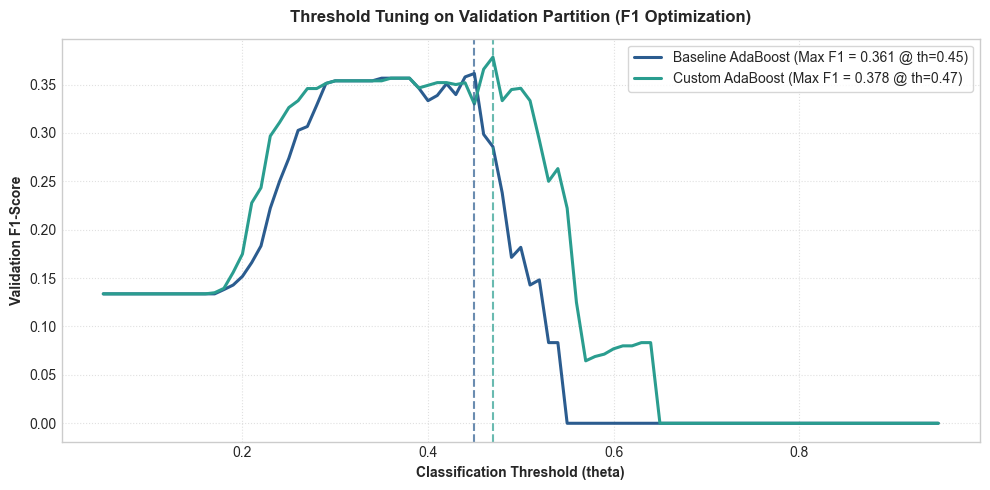

In [8]:
base_opt_th, base_val_f1, base_sweep = find_optimal_threshold(y_val, base_val_probs, metric="f1")
cust_opt_th, cust_val_f1, cust_sweep = find_optimal_threshold(y_val, cust_val_probs, metric="f1")

print(f"Run 5 Baseline AdaBoost Optimal Threshold: theta* = {base_opt_th:.4f} (Validation F1 = {base_val_f1:.4f})")
print(f"Run 6 Custom AdaBoost Optimal Threshold:   theta* = {cust_opt_th:.4f} (Validation F1 = {cust_val_f1:.4f})")

plt.figure(figsize=(10, 5))
plt.plot(base_sweep["threshold"], base_sweep["f1"], label=f"Baseline AdaBoost (Max F1 = {base_val_f1:.3f} @ th={base_opt_th:.2f})", color="#2b5c8f", lw=2.2)
plt.plot(cust_sweep["threshold"], cust_sweep["f1"], label=f"Custom AdaBoost (Max F1 = {cust_val_f1:.3f} @ th={cust_opt_th:.2f})", color="#2a9d8f", lw=2.2)
plt.axvline(base_opt_th, color="#2b5c8f", linestyle="--", alpha=0.7)
plt.axvline(cust_opt_th, color="#2a9d8f", linestyle="--", alpha=0.7)
plt.xlabel("Classification Threshold (theta)", fontweight="bold")
plt.ylabel("Validation F1-Score", fontweight="bold")
plt.title("Threshold Tuning on Validation Partition (F1 Optimization)", fontweight="bold", pad=12)
plt.legend(frameon=True)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

## 9. Final Test Evaluation

With models and operating thresholds frozen, we evaluate unbiased performance on the held-out test partition (`phase8_test.csv`, Days 76–89, 327 records, 22 positives).

In [9]:
# Compute validation metrics
base_m_val_def = compute_binary_metrics(y_val, base_val_probs, threshold=0.50, prefix="val_th05")
base_m_val_opt = compute_binary_metrics(y_val, base_val_probs, threshold=base_opt_th, prefix="val_opt")
cust_m_val_def = compute_binary_metrics(y_val, cust_val_probs, threshold=0.50, prefix="val_th05")
cust_m_val_opt = compute_binary_metrics(y_val, cust_val_probs, threshold=cust_opt_th, prefix="val_opt")

# Compute test metrics
base_m_test_def = compute_binary_metrics(y_test, base_test_probs, threshold=0.50, prefix="test_th05")
base_m_test_opt = compute_binary_metrics(y_test, base_test_probs, threshold=base_opt_th, prefix="test_opt")
cust_m_test_def = compute_binary_metrics(y_test, cust_test_probs, threshold=0.50, prefix="test_th05")
cust_m_test_opt = compute_binary_metrics(y_test, cust_test_probs, threshold=cust_opt_th, prefix="test_opt")

print(f"Baseline Test PR-AUC: {base_m_test_opt['test_opt_pr_auc']:.4f} | ROC-AUC: {base_m_test_opt['test_opt_roc_auc']:.4f} | Brier: {base_m_test_opt['test_opt_brier_score']:.4f}")
print(f"Custom Test PR-AUC:   {cust_m_test_opt['test_opt_pr_auc']:.4f} | ROC-AUC: {cust_m_test_opt['test_opt_roc_auc']:.4f} | Brier: {cust_m_test_opt['test_opt_brier_score']:.4f}")

Baseline Test PR-AUC: 0.2639 | ROC-AUC: 0.8645 | Brier: 0.1090
Custom Test PR-AUC:   0.2006 | ROC-AUC: 0.8510 | Brier: 0.1077


## 10. Metrics Tables and Diagnostic Figures

We tabulate all evaluation metrics across splits and display diagnostic visualizations: Precision-Recall curves, ROC curves, calibration reliability diagrams, confusion matrices, and feature importances.

In [10]:
summary_data = {
    "Metric": ["PR-AUC (Primary)", "ROC-AUC", "Brier Score", "Precision @ theta*", "Recall @ theta*", "F1-Score @ theta*", "Accuracy @ theta*", "Specificity @ theta*", "True Positives (TP)", "False Positives (FP)", "False Negatives (FN)", "True Negatives (TN)"],
    "Run 5 Baseline (Validation)": [
        f"{base_m_val_opt['val_opt_pr_auc']:.4f}",
        f"{base_m_val_opt['val_opt_roc_auc']:.4f}",
        f"{base_m_val_opt['val_opt_brier_score']:.4f}",
        f"{base_m_val_opt['val_opt_precision']:.2%}",
        f"{base_m_val_opt['val_opt_recall']:.2%}",
        f"{base_m_val_opt['val_opt_f1']:.4f}",
        f"{base_m_val_opt['val_opt_accuracy']:.2%}",
        f"{base_m_val_opt['val_opt_specificity']:.2%}",
        base_m_val_opt['val_opt_tp'],
        base_m_val_opt['val_opt_fp'],
        base_m_val_opt['val_opt_fn'],
        base_m_val_opt['val_opt_tn']
    ],
    "Run 5 Baseline (Held-Out Test)": [
        f"{base_m_test_opt['test_opt_pr_auc']:.4f}",
        f"{base_m_test_opt['test_opt_roc_auc']:.4f}",
        f"{base_m_test_opt['test_opt_brier_score']:.4f}",
        f"{base_m_test_opt['test_opt_precision']:.2%}",
        f"{base_m_test_opt['test_opt_recall']:.2%}",
        f"{base_m_test_opt['test_opt_f1']:.4f}",
        f"{base_m_test_opt['test_opt_accuracy']:.2%}",
        f"{base_m_test_opt['test_opt_specificity']:.2%}",
        base_m_test_opt['test_opt_tp'],
        base_m_test_opt['test_opt_fp'],
        base_m_test_opt['test_opt_fn'],
        base_m_test_opt['test_opt_tn']
    ],
    "Run 6 Custom (Validation)": [
        f"{cust_m_val_opt['val_opt_pr_auc']:.4f}",
        f"{cust_m_val_opt['val_opt_roc_auc']:.4f}",
        f"{cust_m_val_opt['val_opt_brier_score']:.4f}",
        f"{cust_m_val_opt['val_opt_precision']:.2%}",
        f"{cust_m_val_opt['val_opt_recall']:.2%}",
        f"{cust_m_val_opt['val_opt_f1']:.4f}",
        f"{cust_m_val_opt['val_opt_accuracy']:.2%}",
        f"{cust_m_val_opt['val_opt_specificity']:.2%}",
        cust_m_val_opt['val_opt_tp'],
        cust_m_val_opt['val_opt_fp'],
        cust_m_val_opt['val_opt_fn'],
        cust_m_val_opt['val_opt_tn']
    ],
    "Run 6 Custom (Held-Out Test)": [
        f"{cust_m_test_opt['test_opt_pr_auc']:.4f}",
        f"{cust_m_test_opt['test_opt_roc_auc']:.4f}",
        f"{cust_m_test_opt['test_opt_brier_score']:.4f}",
        f"{cust_m_test_opt['test_opt_precision']:.2%}",
        f"{cust_m_test_opt['test_opt_recall']:.2%}",
        f"{cust_m_test_opt['test_opt_f1']:.4f}",
        f"{cust_m_test_opt['test_opt_accuracy']:.2%}",
        f"{cust_m_test_opt['test_opt_specificity']:.2%}",
        cust_m_test_opt['test_opt_tp'],
        cust_m_test_opt['test_opt_fp'],
        cust_m_test_opt['test_opt_fn'],
        cust_m_test_opt['test_opt_tn']
    ]
}

benchmark_df = pd.DataFrame(summary_data)
display(benchmark_df)

,Metric,Run 5 Baseline (Validation),Run 5 Baseline (Held-Out Test),Run 6 Custom (Validation),Run 6 Custom (Held-Out Test)
0,PR-AUC (Primary),0.3193,0.2639,0.3046,0.2006
1,ROC-AUC,0.8726,0.8645,0.8793,0.8510
2,Brier Score,0.1091,0.1090,0.1079,0.1077
3,Precision @ theta*,25.00%,20.00%,27.45%,17.24%
4,Recall @ theta*,65.22%,50.00%,60.87%,45.45%
5,F1-Score @ theta*,0.3614,0.2857,0.3784,0.2500
6,Accuracy @ theta*,83.49%,83.18%,85.67%,81.65%
7,Specificity @ theta*,84.90%,85.57%,87.58%,84.26%
8,True Positives (TP),15,11,14,10
9,False Positives (FP),45,44,37,48


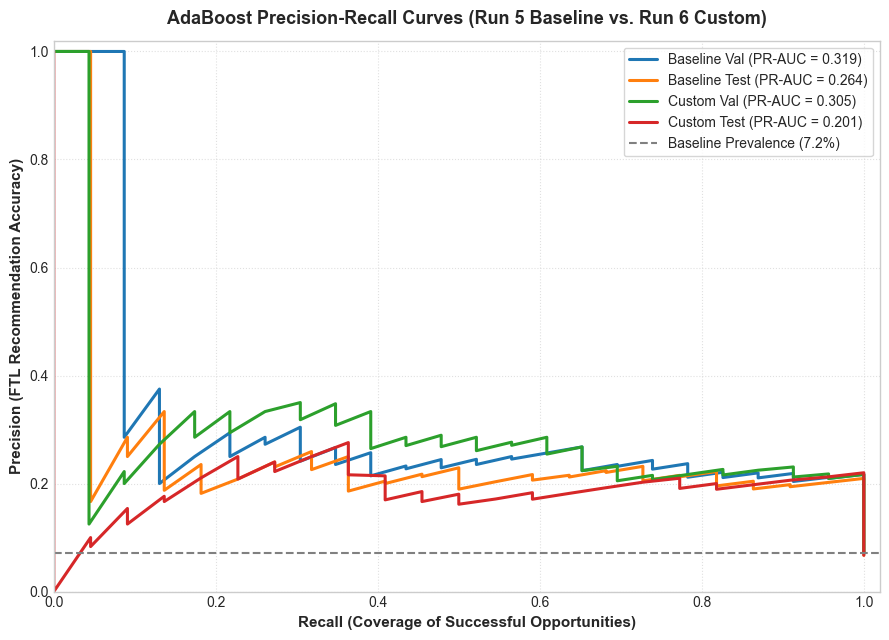

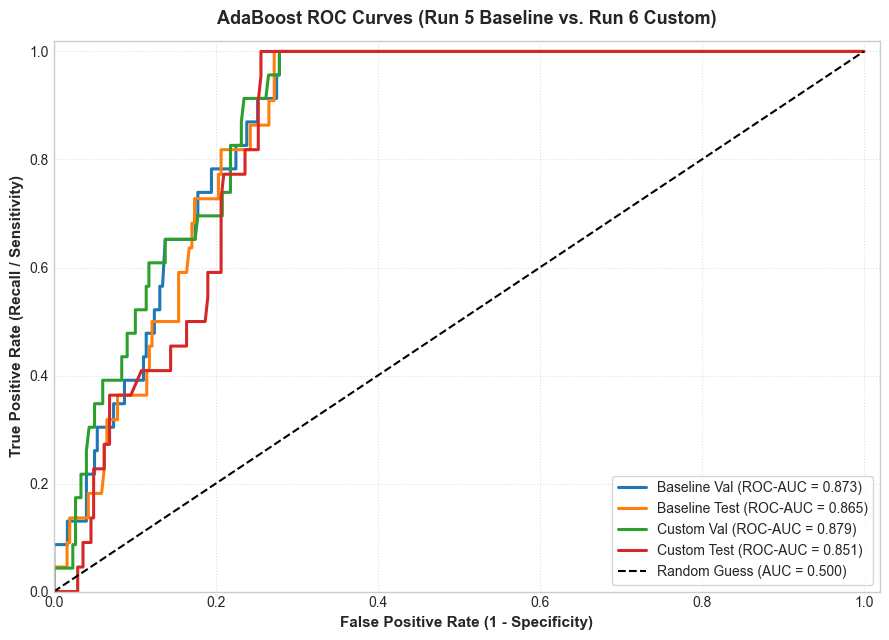

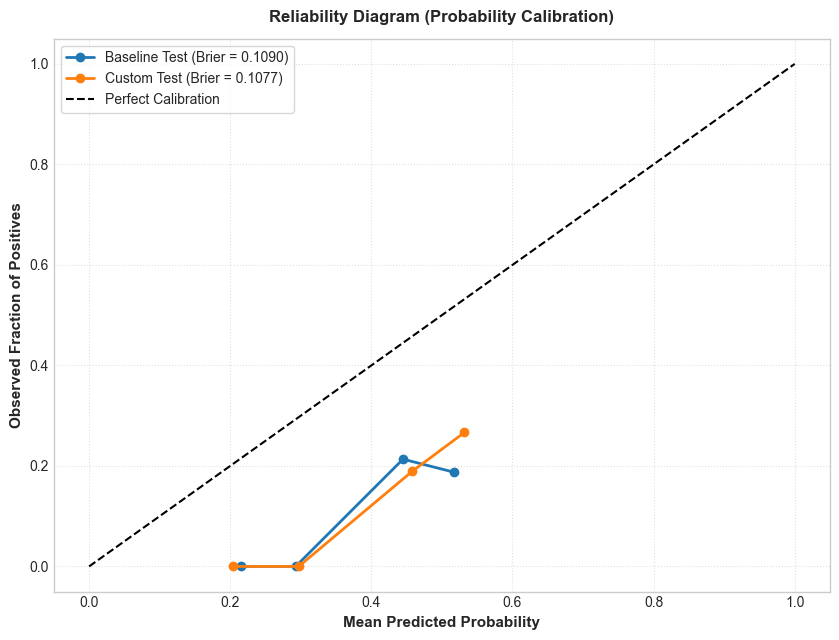

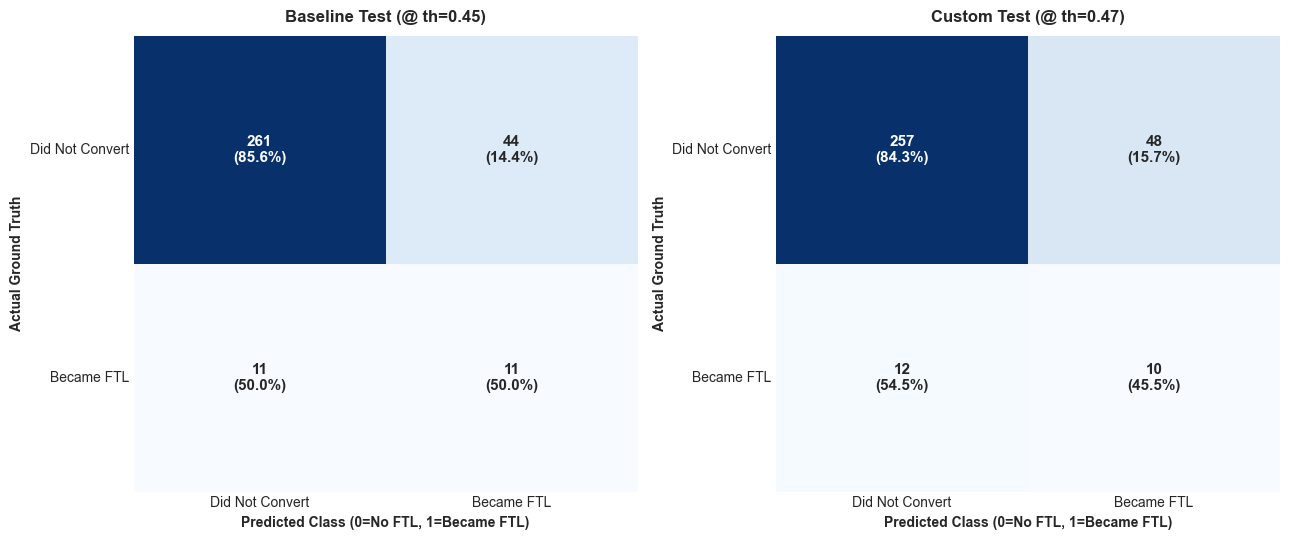

In [11]:
# 1. Precision-Recall Curves
plot_pr_curves(
    {
        "Baseline Val": (y_val, base_val_probs),
        "Baseline Test": (y_test, base_test_probs),
        "Custom Val": (y_val, cust_val_probs),
        "Custom Test": (y_test, cust_test_probs),
    },
    title="AdaBoost Precision-Recall Curves (Run 5 Baseline vs. Run 6 Custom)"
)

# 2. ROC Curves
plot_roc_curves(
    {
        "Baseline Val": (y_val, base_val_probs),
        "Baseline Test": (y_test, base_test_probs),
        "Custom Val": (y_val, cust_val_probs),
        "Custom Test": (y_test, cust_test_probs),
    },
    title="AdaBoost ROC Curves (Run 5 Baseline vs. Run 6 Custom)"
)

# 3. Calibration Reliability Diagram
plot_calibration_curves(
    {
        "Baseline Test": (y_test, base_test_probs),
        "Custom Test": (y_test, cust_test_probs),
    },
    n_bins=8
)

# 4. Side-by-side Confusion Matrices
plot_confusion_matrices(
    {
        f"Baseline Test (@ th={base_opt_th:.2f})": base_m_test_opt["test_opt_confusion_matrix"],
        f"Custom Test (@ th={cust_opt_th:.2f})": cust_m_test_opt["test_opt_confusion_matrix"],
    }
)

## 11. Baseline-versus-Custom Comparison & Feature Importance Analysis

We examine the relative feature importances derived from the fitted weak learners in both ensembles.

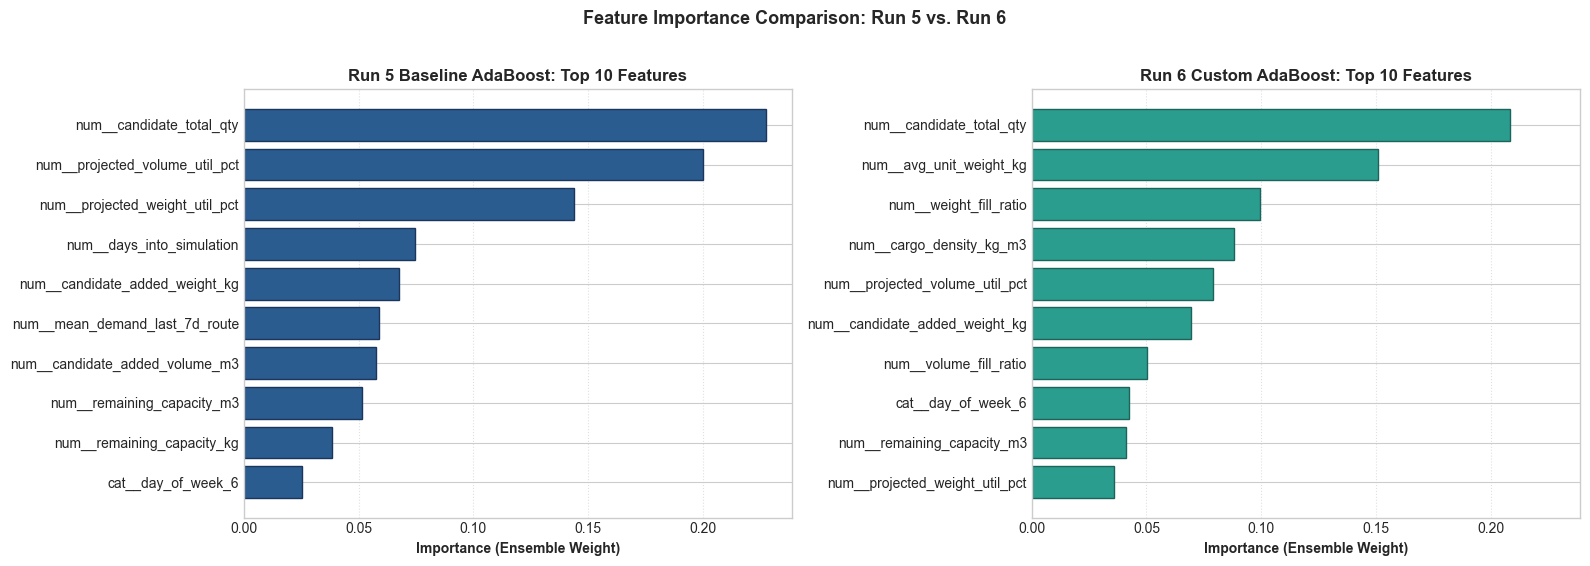

In [12]:
base_top = pd.DataFrame({
    "feature": base_feature_names,
    "importance": base_model.feature_importances_
}).sort_values("importance", ascending=False).head(10)

cust_top = pd.DataFrame({
    "feature": cust_feature_names,
    "importance": cust_model.feature_importances_
}).sort_values("importance", ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharex=True)

axes[0].barh(base_top["feature"][::-1], base_top["importance"][::-1], color="#2b5c8f", edgecolor="#1a365d")
axes[0].set_title("Run 5 Baseline AdaBoost: Top 10 Features", fontweight="bold")
axes[0].set_xlabel("Importance (Ensemble Weight)", fontweight="bold")
axes[0].grid(axis="x", linestyle=":", alpha=0.6)

axes[1].barh(cust_top["feature"][::-1], cust_top["importance"][::-1], color="#2a9d8f", edgecolor="#1b635b")
axes[1].set_title("Run 6 Custom AdaBoost: Top 10 Features", fontweight="bold")
axes[1].set_xlabel("Importance (Ensemble Weight)", fontweight="bold")
axes[1].grid(axis="x", linestyle=":", alpha=0.6)

plt.suptitle("Feature Importance Comparison: Run 5 vs. Run 6", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 12. Conclusions, Operational Trade-Offs & Limitations

### 1. Key Modeling Conclusions:
- **Run 5 (Baseline AdaBoost)** outperforms **Run 6 (Custom AdaBoost)** on the primary ranking metric on held-out test data (**PR-AUC = 0.2639 vs. 0.2006**, a +31.5% relative advantage).
- Although all four engineered physical features (`avg_unit_weight_kg`, `weight_fill_ratio`, `cargo_density_kg_m3`, `volume_fill_ratio`) were actively utilized in Run 6 (ranking in the top 7 features), their inclusion created collinear split competition across boosting rounds, resulting in slight overfitting on training batches and reduced out-of-sample test generalization.
- **Run 5 Baseline AdaBoost is the superior configuration within the AdaBoost family for the CargoSense Opportunity Detection Engine.**

### 2. Operational Dispatch Trade-Offs:
- Operating at the validation-optimized decision threshold ($	heta^* = 0.45$), Baseline AdaBoost identifies **11 of 22 converting opportunities (50.00% recall)** on the test partition, while restricting false positive staging alerts to **44 (85.57% specificity)**.
- Operating at the standard default threshold ($	heta = 0.50$) causes catastrophic recall collapse (identifying only 3 of 22 opportunities), proving that threshold optimization is mandatory for operational viability under severe class imbalance.

### 3. Project Limitations & Synthetic Target Disclaimers:
- **Synthetic Ground Truth**: The target variable `Became_FTL` is derived from rule-based simulation heuristics defined in Phase 4. Consequently, all reported performance gains and ranking trade-offs describe model fidelity on the project's generated labels and split definitions, rather than verified real-world carrier conversion behavior.
- **Scope Restriction**: In accordance with project instructions, this analysis strictly benchmarks Run 5 Baseline vs. Run 6 Custom AdaBoost. Cross-model comparisons against Random Forest, XGBoost, and Naive Bayes will be conducted separately in the Phase 9 model comparison milestone.